In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori,association_rules

In [3]:
data=pd.read_csv("orders.csv")
data.head(5)

,id,order_date,ship_mode,customer_id,sales
0,100006,2014-09-07,Standard,DK-13375,377.970
1,100090,2014-07-08,Standard,EB-13705,699.192
2,100293,2014-03-14,Standard,NF-18475,91.056
3,100328,2014-01-28,Standard,JC-15340,3.928
4,100363,2014-04-08,Standard,JM-15655,21.376


In [4]:
# remove unnecessary col
data=data.dropna()
data=data.dropna(subset=['ship_mode','customer_id'])

In [6]:
# create new cols
data['sales_category']=data['sales'].apply(
    lambda x: 'High Sales' if x>=data['sales'].median()
    else 'Low Sales'
)

data.head(5)

,id,order_date,ship_mode,customer_id,sales,sales_category
0,100006,2014-09-07,Standard,DK-13375,377.970,High Sales
1,100090,2014-07-08,Standard,EB-13705,699.192,High Sales
2,100293,2014-03-14,Standard,NF-18475,91.056,Low Sales
3,100328,2014-01-28,Standard,JC-15340,3.928,Low Sales
4,100363,2014-04-08,Standard,JM-15655,21.376,Low Sales


In [8]:
transactions=[]

for i in range(len(data)):
    transaction=[
        data.iloc[i]['ship_mode'],
        data.iloc[i]['sales_category']
    ]
    transactions.append(transaction)

print(transactions[:5])

[['Standard', 'High Sales'], ['Standard', 'High Sales'], ['Standard', 'Low Sales'], ['Standard', 'Low Sales'], ['Standard', 'Low Sales']]


In [9]:
# encode
te=TransactionEncoder()

encoded_data=te.fit(transactions).transform(transactions)

encoded_data[:5]

array([[False,  True, False, False, False,  True],
       [False,  True, False, False, False,  True],
       [False, False,  True, False, False,  True],
       [False, False,  True, False, False,  True],
       [False, False,  True, False, False,  True]])

In [10]:
df=pd.DataFrame(encoded_data,columns=te.columns_)

df.head(5)

,First,High Sales,Low Sales,Same Day,Second,Standard
0,False,True,False,False,False,True
1,False,True,False,False,False,True
2,False,False,True,False,False,True
3,False,False,True,False,False,True
4,False,False,True,False,False,True


In [11]:
frequent_items=apriori(df,min_support=0.1,use_colnames=True)
print(frequent_items)

    support                itemsets
0  0.157117                 (First)
1  0.500100            (High Sales)
2  0.499900             (Low Sales)
3  0.192454                (Second)
4  0.597724              (Standard)
5  0.100619    (High Sales, Second)
6  0.295269  (High Sales, Standard)
7  0.302456   (Low Sales, Standard)


In [12]:
rules=association_rules(frequent_items,metric='confidence',min_threshold=0.1)

print(rules)

    antecedents   consequents  antecedent support  consequent support  \
0  (High Sales)      (Second)            0.500100            0.192454   
1      (Second)  (High Sales)            0.192454            0.500100   
2  (High Sales)    (Standard)            0.500100            0.597724   
3    (Standard)  (High Sales)            0.597724            0.500100   
4   (Low Sales)    (Standard)            0.499900            0.597724   
5    (Standard)   (Low Sales)            0.597724            0.499900   

    support  confidence      lift  representativity  leverage  conviction  \
0  0.100619    0.201198  1.045434               1.0  0.004373    1.010946   
1  0.100619    0.522822  1.045434               1.0  0.004373    1.047617   
2  0.295269    0.590419  0.987779               1.0 -0.003653    0.982165   
3  0.295269    0.493988  0.987779               1.0 -0.003653    0.987922   
4  0.302456    0.605032  1.012226               1.0  0.003653    1.018502   
5  0.302456    0.506012  1

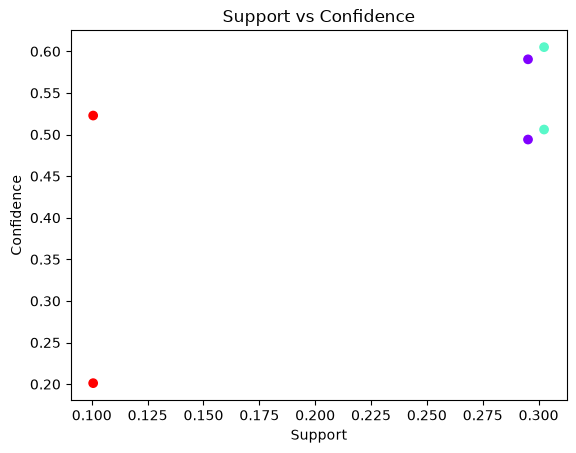

In [13]:
plt.scatter(rules['support'],rules['confidence'],c=rules['lift'],cmap='rainbow')
plt.xlabel("Support")
plt.ylabel("Confidence")
plt.title("Support vs Confidence")
plt.show()

In [14]:
support_values=[0.1,0.2,0.3,0.4]

counts=[]
for val in support_values:
    count=(rules['support']>=val).sum()
    counts.append(count)
print(counts)

[np.int64(6), np.int64(4), np.int64(2), np.int64(0)]


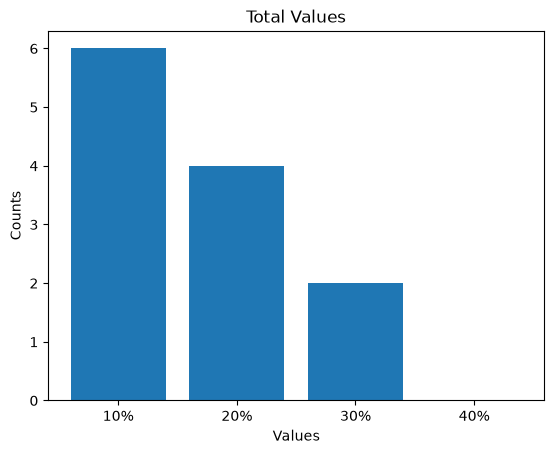

In [17]:
plt.bar(['10%','20%','30%','40%'],counts)
plt.xlabel("Values")
plt.ylabel("Counts")
plt.title("Total Values")

plt.show()